Implementation of grokking phenomenon.

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import os


In [ ]:


class GrokkingTransformer(nn.Module):
    def __init__(self, p=113, d_model=128, n_heads=4, d_mlp=512):
        super().__init__()
        self.p = p
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.d_mlp = d_mlp

        self.W_E = nn.Embedding(p + 1, d_model)
        self.W_pos = nn.Parameter(torch.randn(3, d_model) * (1.0 / np.sqrt(d_model)))

        self.W_Q = nn.Parameter(torch.randn(n_heads, d_model, self.d_head) / np.sqrt(d_model))
        self.W_K = nn.Parameter(torch.randn(n_heads, d_model, self.d_head) / np.sqrt(d_model))
        self.W_V = nn.Parameter(torch.randn(n_heads, d_model, self.d_head) / np.sqrt(d_model))
        self.W_O = nn.Parameter(torch.randn(n_heads, self.d_head, d_model) / np.sqrt(d_model))

        self.W_in = nn.Linear(d_model, d_mlp, bias=True)
        self.W_out = nn.Linear(d_mlp, d_model, bias=False)
        self.W_U = nn.Linear(d_model, p, bias=False)

    def forward(self, x, return_activations=False):
        res = self.W_E(x) + self.W_pos.unsqueeze(0)

        q = torch.einsum('bsd,hde->hbse', res, self.W_Q)
        k = torch.einsum('bsd,hde->hbse', res, self.W_K)
        v = torch.einsum('bsd,hde->hbse', res, self.W_V)

        scores = torch.einsum('hbie,hbje->hbij', q, k) / np.sqrt(self.d_head)
        attn_weights = F.softmax(scores, dim=-1)

        attn_out = torch.einsum('hbij,hbje->hbie', attn_weights, v)
        attn_res = torch.einsum('hbie,hed->bid', attn_out, self.W_O)
        res = res + attn_res

        final_token_res = res[:, 2, :]
        mlp_act = F.relu(self.W_in(final_token_res))
        mlp_out = self.W_out(mlp_act)
        final_res = final_token_res + mlp_out
        logits = self.W_U(final_res)

        if return_activations:
            return logits, mlp_act, attn_weights
        return logits



def get_fourier_basis(p):
    """Generates normalized 1D discrete Fourier basis vectors for mod p."""
    half_p = (p - 1) // 2
    basis = []
    # Constant component (k=0)
    basis.append(np.ones(p) / np.sqrt(p))
    # Cosine and Sine pairs for frequencies k=1..half_p
    for k in range(1, half_p + 1):
        theta = 2 * np.pi * k * np.arange(p) / p
        basis.append(np.cos(theta) * np.sqrt(2 / p))
        basis.append(np.sin(theta) * np.sqrt(2 / p))
    return np.stack(basis, axis=0)  # Shape: (p, p)


def compute_fourier_norms_1d(weight_matrix, p=113):
    """
    Computes L2 norm of Fourier components of a matrix along the token axis.
    weight_matrix: (p, hidden_dim)
    """
    F_basis = get_fourier_basis(p)  # (p, p)
    # Project into Fourier basis: (p_freq, hidden_dim)
    fourier_coeffs = F_basis @ weight_matrix
    # Norm along hidden dimension for each frequency component
    norms = np.linalg.norm(fourier_coeffs, axis=1)

    # Group into frequencies k=1..half_p (summing cos and sin energy)
    half_p = (p - 1) // 2
    cos_norms = norms[1::2]
    sin_norms = norms[2::2]
    total_k_norms = np.sqrt(cos_norms**2 + sin_norms**2)
    return total_k_norms  # Length: half_p



def train_and_capture_mechanics():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(42)
    np.random.seed(42)

    p = 113
    train_frac = 0.3
    epochs = 60000
    lr = 1e-3
    weight_decay = 2.0

    pairs = [(a, b) for a in range(p) for b in range(p)]
    np.random.shuffle(pairs)
    n_train = int(len(pairs) * train_frac)

    def to_tensors(data):
        a = torch.tensor([x[0] for x in data], dtype=torch.long)
        b = torch.tensor([x[1] for x in data], dtype=torch.long)
        eq = torch.full_like(a, p)
        return torch.stack([a, b, eq], dim=1), (a + b) % p

    train_inputs, train_targets = [t.to(device) for t in to_tensors(pairs[:n_train])]
    test_inputs, test_targets = [t.to(device) for t in to_tensors(pairs[n_train:])]

    # Precompute full grid tensor for mapping full-space activations
    grid_a, grid_b = torch.meshgrid(torch.arange(p), torch.arange(p), indexing='ij')
    all_a = grid_a.flatten().to(device)
    all_b = grid_b.flatten().to(device)
    all_eq = torch.full_like(all_a, p).to(device)
    full_grid_inputs = torch.stack([all_a, all_b, all_eq], dim=1)

    model = GrokkingTransformer(p=p, d_model=128, n_heads=4, d_mlp=512).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay, betas=(0.9, 0.98))
    criterion = nn.CrossEntropyLoss()

    checkpoints = [500, 3000, 8000, 20000 , 30000 , 40000 , 60000]
    snapshots = {}

    print(f"Training transformer on Modular Addition (p={p}) across {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        logits = model(train_inputs)
        loss = criterion(logits, train_targets)
        loss.backward()

        optimizer.step()

        if epoch in checkpoints:
            model.eval()
            with torch.no_grad():
                test_logits = model(test_inputs)
                test_loss = criterion(test_logits, test_targets).item()
                test_acc = (test_logits.argmax(-1) == test_targets).float().mean().item()

                # Full grid logits and MLP activations
                grid_logits, grid_mlp_act, _ = model(full_grid_inputs, return_activations=True)

                # 1. Embedding Matrix W_E (tokens 0..p-1)
                W_E_np = model.W_E.weight[:p, :].detach().cpu().numpy()
                we_fourier_norms = compute_fourier_norms_1d(W_E_np, p=p)

                # 2. Neuron-Logit Map: W_L = W_U @ W_out (p, d_mlp)
                W_L_np = (model.W_U.weight @ model.W_out.weight).detach().cpu().numpy()
                wl_fourier_norms = compute_fourier_norms_1d(W_L_np, p=p)

                # 3. Output Logit grid for target c = 0: shape (p, p)
                # Gives logit(c=0) as a function of inputs a and b
                logit_c0_grid = grid_logits[:, 0].view(p, p).cpu().numpy()

                # 4. Neuron 0 activation across full (a, b) grid
                neuron0_grid = grid_mlp_act[:, 0].view(p, p).cpu().numpy()

                snapshots[epoch] = {
                    "we_fourier": we_fourier_norms,
                    "wl_fourier": wl_fourier_norms,
                    "logit_grid": logit_c0_grid,
                    "neuron_grid": neuron0_grid,
                    "test_acc": test_acc,
                    "test_loss": test_loss
                }

            print(f"Captured Epoch {epoch:5d} | Test Loss: {test_loss:.4e} | Test Acc: {test_acc*100:5.1f}%")

    return model, snapshots, p, device


def plot_mechanistic_evolution(snapshots, p, target_neuron_grid):
    checkpoints = list(snapshots.keys())
    half_p = (p - 1) // 2
    freq_axis = np.arange(1, half_p + 1)

    fig = plt.figure(figsize=(20, 16))
    gs = fig.add_gridspec(4, len(checkpoints), height_ratios=[1, 1, 1.2, 1.2])

    # Row 1: Fourier Spectrum of Embedding Matrix W_E
    for i, ep in enumerate(checkpoints):
        ax = fig.add_subplot(gs[0, i])
        ax.bar(freq_axis, snapshots[ep]["we_fourier"], color="steelblue", width=0.8)
        ax.set_title(f"Epoch {ep}: $W_E$ Fourier Norms\n(Acc: {snapshots[ep]['test_acc']*100:.1f}%)", fontsize=11)
        ax.set_xlabel("Frequency $k$")
        ax.set_ylabel(r"$\| \mathcal{F}(W_E)_k \|_2$")
        ax.set_xlim(0, half_p + 1)
        ax.grid(True, alpha=0.25)

    # Row 2: Fourier Spectrum of Neuron-Logit Map W_L (W_U @ W_out)
    for i, ep in enumerate(checkpoints):
        ax = fig.add_subplot(gs[1, i])
        ax.bar(freq_axis, snapshots[ep]["wl_fourier"], color="darkorange", width=0.8)
        ax.set_title(f"Epoch {ep}: $W_L$ Fourier Norms", fontsize=11)
        ax.set_xlabel("Frequency $k$")
        ax.set_ylabel(r"$\| \mathcal{F}(W_L)_k \|_2$")
        ax.set_xlim(0, half_p + 1)
        ax.grid(True, alpha=0.25)

    # Row 3: Emergence of Diagonal Wave in Final Logit Grid Logit(c=0)
    for i, ep in enumerate(checkpoints):
        ax = fig.add_subplot(gs[2, i])
        im = ax.imshow(snapshots[ep]["logit_grid"], cmap="coolwarm", origin="lower")
        ax.set_title(f"Epoch {ep}: $\\mathrm{{Logit}}(c=0)$\nOver Inputs $(a, b)$", fontsize=11)
        ax.set_xlabel("Input $a$")
        ax.set_ylabel("Input $b$")
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Row 4: Final Trained Neuron Analysis (Spatial Pattern & 2D DFT)
    # Col 0: Final Neuron Activation Grid
    ax_n0 = fig.add_subplot(gs[3, 0])
    im_n0 = ax_n0.imshow(target_neuron_grid, cmap="viridis", origin="lower")
    ax_n0.set_title("Trained Neuron Activations\n$MLP(a, b)$", fontsize=11)
    ax_n0.set_xlabel("Input $a$")
    ax_n0.set_ylabel("Input $b$")
    plt.colorbar(im_n0, ax=ax_n0, fraction=0.046, pad=0.04)

    # Col 1: 2D DFT Magnitude Spectrum of the Neuron
    fft_neuron = np.fft.fft2(target_neuron_grid)
    fft_power = np.abs(fft_neuron)**2
    fft_power[0, 0] = 0.0  # Zero out DC

    ax_dft = fig.add_subplot(gs[3, 1])
    im_dft = ax_dft.imshow(np.log1p(np.fft.fftshift(fft_power)), cmap="magma", origin="lower")
    ax_dft.set_title("Neuron 2D DFT (Shifted)\nMagnitude Spectrum", fontsize=11)
    ax_dft.set_xlabel(r"Freq $k_a$")
    ax_dft.set_ylabel(r"Freq $k_b$")
    plt.colorbar(im_dft, ax=ax_dft, fraction=0.046, pad=0.04)

    # Col 2: 1D Radial/Diagonal Power Projection to Isolate Dominant Frequency
    diag_energy = np.zeros(half_p + 1)
    for k in range(1, half_p + 1):
        diag_energy[k] = (fft_power[k, k] + fft_power[p - k, p - k] +
                          fft_power[k, p - k] + fft_power[p - k, k])
    top_k = np.argmax(diag_energy)

    ax_spec = fig.add_subplot(gs[3, 2])
    ax_spec.plot(freq_axis, diag_energy[1:], color="crimson", lw=2)
    ax_spec.axvline(top_k, color="black", linestyle="--", alpha=0.7, label=f"Peak $k={top_k}$")
    ax_spec.set_title(f"Constituent Frequency Extraction\nDominant Mode $k={top_k}$", fontsize=11)
    ax_spec.set_xlabel("Frequency $k$")
    ax_spec.set_ylabel("Spectral Energy")
    ax_spec.legend()
    ax_spec.grid(True, alpha=0.3)

    # Col 3: Mathematical Description
    ax_text = fig.add_subplot(gs[3, 3])
    ax_text.axis('off')
    summary_box = (
        f"MECHANISTIC DECOMPOSITION\n"
        f"------------------------------------\n"
        f"Prime Modulus P: {p}\n"
        f"Dominant Mode: k = {top_k}\n"
        f"Frequency: w_{{{top_k}}} = 2π({top_k})/{p}\n\n"
        f"Mathematical Mechanism:\n"
        f"1. W_E projects a, b to cos/sin(w_k * x)\n"
        f"2. MLP forms cos(w_k(a+b)) via:\n"
        f"   cos(w_k a)cos(w_k b) - sin(w_k a)sin(w_k b)\n"
        f"3. W_L reads off cos(w_k(a+b - c))\n"
        f"   giving the diagonal line:\n"
        f"   a + b ≡ c (mod {p})"
    )
    ax_text.text(0.02, 0.5, summary_box, fontsize=10, family='monospace', verticalalignment='center',
                 bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    model, snapshots, p, device = train_and_capture_mechanics()

    # Extract final activations of neuron 0 across all (a, b) pairs
    grid_a, grid_b = torch.meshgrid(torch.arange(p), torch.arange(p), indexing='ij')
    all_inputs = torch.stack([grid_a.flatten(), grid_b.flatten(), torch.full((p*p,), p)], dim=1).to(device)

    model.eval()
    with torch.no_grad():
        _, mlp_acts, _ = model(all_inputs, return_activations=True)
        final_neuron0_grid = mlp_acts[:, 0].view(p, p).cpu().numpy()

    plot_mechanistic_evolution(snapshots, p, final_neuron0_grid)

In [ ]:

def visualize_embedding_geometry(model, p=113, key_frequencies=[8, 26, 30], non_key_freq=5):
    """
    Projects the embedding matrix W_E onto 2D Fourier bases for key vs non-key frequencies.
    """
    # Extract token embeddings for 0 .. p-1 (shape: p x d_model)
    W_E = model.W_E.weight[:p, :].detach().cpu().numpy()

    # Define frequencies to visualize: key frequencies + one non-key frequency for comparison
    frequencies_to_plot = key_frequencies + [non_key_freq]
    n_plots = len(frequencies_to_plot)

    fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 5))

    tokens = np.arange(p)

    for idx, k in enumerate(frequencies_to_plot):
        ax = axes[idx]
        is_key = k in key_frequencies

        # 1. Create normalized 1D Fourier basis vectors for frequency k
        theta = 2 * np.pi * k * tokens / p
        basis_cos = np.cos(theta) * np.sqrt(2 / p)  # shape: (p,)
        basis_sin = np.sin(theta) * np.sqrt(2 / p)  # shape: (p,)

        # 2. Project the full embedding matrix onto this 2D Fourier subspace
        # W_E has shape (p, d_model) -> projection gives (d_model,) vector for each basis
        v_cos = basis_cos @ W_E  # Direction of cos(w_k * x) in embedding space
        v_sin = basis_sin @ W_E  # Direction of sin(w_k * x) in embedding space

        # Normalize directions to form an orthonormal 2D viewing plane
        v_cos = v_cos / (np.linalg.norm(v_cos) + 1e-8)
        v_sin = v_sin / (np.linalg.norm(v_sin) + 1e-8)

        # 3. Project each token embedding onto these 2 directions
        x_coords = W_E @ v_cos  # (p,)
        y_coords = W_E @ v_sin  # (p,)

        # 4. Plot the 2D projected tokens
        scatter = ax.scatter(
            x_coords, y_coords,
            c=tokens, cmap="hsv", s=60, edgecolors='black', linewidth=0.5, zorder=3
        )

        # Connect consecutive numbers with lines to show the trajectory/winding
        ax.plot(x_coords, y_coords, color='gray', alpha=0.35, linestyle='-', zorder=2)

        # Annotate a few token numbers along the ring
        for step in [0, p//4, p//2, 3*p//4]:
            ax.text(
                x_coords[step] * 1.15, y_coords[step] * 1.15,
                str(step), fontsize=9, fontweight='bold', ha='center', va='center'
            )

        title = f"Key Freq $k={k}$ (Ordered Ring)" if is_key else f"Non-Key Freq $k={k}$ (Noise)"
        ax.set_title(title, fontsize=11, color="navy" if is_key else "darkred")
        ax.set_xlabel(r"Projection on $\cos(\omega_k x)$")
        ax.set_ylabel(r"Projection on $\sin(\omega_k x)$")
        ax.axhline(0, color='black', lw=0.5, ls='--', alpha=0.5)
        ax.axvline(0, color='black', lw=0.5, ls='--', alpha=0.5)
        ax.grid(True, alpha=0.2)
        ax.set_aspect('equal')

    # Add a shared colorbar indicating the token value
    cbar = fig.colorbar(scatter, ax=axes.ravel().tolist(), orientation='horizontal', fraction=0.04, pad=0.15)
    cbar.set_label("Token Index $x \in \{0, 1, \dots, P-1\}$", fontsize=11)

    plt.suptitle(f"Geometry of Embedding Space $W_E$ Projected onto Fourier Bases ($P={p}$)", fontsize=14, y=1.05)
    plt.show()


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_embedding_geometry(model, p=113, key_frequencies=[8, 26, 31], non_key_freq=5)

In [16]:

class ModularArithmeticInspector:
    """
    Modular inspector for reverse-engineering the final layers and
    class-specific activation patterns of a trained modular arithmetic Transformer.
    """
    def __init__(self, model, p=113, device=None):
        self.model = model
        self.p = p
        self.device = device or next(model.parameters()).device
        self.half_p = (p - 1) // 2

        # Cache full grid activations
        self.all_logits = None
        self.all_mlp_acts = None
        self._compute_full_grid_forward()

    @torch.no_grad()
    def _compute_full_grid_forward(self):
        """Runs a forward pass across all p x p input pairs (a, b)."""
        self.model.eval()
        grid_a, grid_b = torch.meshgrid(torch.arange(self.p), torch.arange(self.p), indexing='ij')
        all_a = grid_a.flatten().to(self.device)
        all_b = grid_b.flatten().to(self.device)
        all_eq = torch.full_like(all_a, self.p).to(self.device)
        full_inputs = torch.stack([all_a, all_b, all_eq], dim=1)

        # Handle models returning (logits, mlp_acts, attn_weights) or (logits, mlp_acts)
        out = self.model(full_inputs, return_activations=True)
        if len(out) == 3:
            logits, mlp_acts, _ = out
        else:
            logits, mlp_acts = out

        # Reshape to grid: (p, p, p) for logits, (p, p, d_mlp) for MLP
        self.all_logits = logits.view(self.p, self.p, self.p).cpu().numpy()
        self.all_mlp_acts = mlp_acts.view(self.p, self.p, -1).cpu().numpy()

    def get_logit_surface(self, target_c):
        """Returns the 2D logit surface of shape (p, p) for target class c."""
        return self.all_logits[:, :, target_c]

    def get_neuron_logit_weights(self, target_c):
        """
        Extracts the effective weight vector from all MLP neurons to class c:
        W_L[c] = (W_U @ W_out)[c, :] of shape (d_mlp,)
        """
        W_L = (self.model.W_U.weight @ self.model.W_out.weight).detach().cpu().numpy()
        return W_L[target_c, :]

    def compute_2d_dft(self, grid_2d):
        """Computes 2D DFT and 1D symmetric frequency spectrum."""
        fft_2d = np.fft.fft2(grid_2d)
        power_2d = np.abs(fft_2d) ** 2
        power_2d[0, 0] = 0.0  # Zero out DC

        # Group diagonal / anti-diagonal energies into frequencies k = 1 .. half_p
        f_power_1d = np.zeros(self.half_p + 1)
        for k in range(1, self.half_p + 1):
            f_power_1d[k] = (power_2d[k, k] + power_2d[self.p - k, self.p - k] +
                             power_2d[k, self.p - k] + power_2d[self.p - k, k])
        return power_2d, f_power_1d

    def inspect_class(self, target_c, top_neurons_k=3):
        """
        Full diagnostic dashboard for class c:
        1. Output Logit Surface
        2. 2D DFT Spectrum of Class c
        3. 1D Frequency Spectrum of Class c
        4. Top-k contributing MLP neurons and their frequency spectra
        """
        logit_grid = self.get_logit_surface(target_c)
        power_2d, f_power_1d = self.compute_2d_dft(logit_grid)
        top_k_class_freqs = np.argsort(f_power_1d)[-3:][::-1]

        # Find top contributing neurons to class c
        w_L_c = self.get_neuron_logit_weights(target_c)
        top_neuron_indices = np.argsort(np.abs(w_L_c))[-top_neurons_k:][::-1]

        # Plotting Setup
        fig = plt.figure(figsize=(18, 10))
        gs = fig.add_gridspec(2, 4, height_ratios=[1.1, 1])

        # --- Row 1: Class-Level Logit Analysis ---
        # Panel 1: Logit Surface
        ax1 = fig.add_subplot(gs[0, 0])
        im1 = ax1.imshow(logit_grid, cmap="coolwarm", origin="lower")
        ax1.set_title(f"Logit Surface: Class $c={target_c}$\n$a + b \\equiv {target_c}\\ (\\mathrm{{mod}}\\ {self.p})$", fontsize=11)
        ax1.set_xlabel("Input $a$")
        ax1.set_ylabel("Input $b$")
        plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

        # Panel 2: 2D DFT Spectrum (Shifted)
        ax2 = fig.add_subplot(gs[0, 1])
        im2 = ax2.imshow(np.log1p(np.fft.fftshift(power_2d)), cmap="magma", origin="lower")
        ax2.set_title(f"2D DFT Power (Shifted)\nLogit Grid $c={target_c}$", fontsize=11)
        ax2.set_xlabel(r"Freq $k_a$")
        ax2.set_ylabel(r"Freq $k_b$")
        plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

        # Panel 3: 1D Constituent Frequency Spectrum
        ax3 = fig.add_subplot(gs[0, 2])
        freq_axis = np.arange(1, self.half_p + 1)
        ax3.plot(freq_axis, f_power_1d[1:], color="crimson", lw=2)
        for k in top_k_class_freqs:
            ax3.axvline(k, color="black", linestyle="--", alpha=0.5, label=f"Mode $k={k}$")
        ax3.set_title(f"Constituent Frequencies for Class $c={target_c}$", fontsize=11)
        ax3.set_xlabel("Frequency $k$")
        ax3.set_ylabel("Spectral Energy")
        ax3.legend(fontsize=9)
        ax3.grid(True, alpha=0.3)

        # Panel 4: Mathematical Summary Box
        ax4 = fig.add_subplot(gs[0, 3])
        ax4.axis('off')
        summary_text = (
            f"TARGET CLASS: c = {target_c}\n"
            f"------------------------------------\n"
            f"Modulus P: {self.p}\n"
            f"Dominant Frequencies:\n"
            + "\n".join([f"  • k = {k} (w = 2π*{k}/{self.p})" for k in top_k_class_freqs])
            + f"\n\nTop {top_neurons_k} Neurons Feeding Class {target_c}:\n"
            + "\n".join([f"  • Neuron {n_idx}: W_L weight = {w_L_c[n_idx]:+.3f}" for n_idx in top_neuron_indices])
            + f"\n\nLogit Wavefront Equation:\n"
            f"Logit(c) ∝ ∑ cos(w_k(a + b - {target_c}))"
        )
        ax4.text(0.05, 0.5, summary_text, fontsize=9.5, family='monospace', verticalalignment='center',
                 bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

        # --- Row 2: Top Contributing Neuron Activations ---
        for i, n_idx in enumerate(top_neuron_indices):
            neuron_acts = self.all_mlp_acts[:, :, n_idx]
            _, n_f_power = self.compute_2d_dft(neuron_acts)
            n_top_k = np.argmax(n_f_power)

            ax_n = fig.add_subplot(gs[1, i])
            im_n = ax_n.imshow(neuron_acts, cmap="viridis", origin="lower")
            ax_n.set_title(f"Neuron {n_idx} Activations\nMode $k={n_top_k}$ | Weight: {w_L_c[n_idx]:+.2f}", fontsize=10)
            ax_n.set_xlabel("Input $a$")
            ax_n.set_ylabel("Input $b$")
            plt.colorbar(im_n, ax=ax_n, fraction=0.046, pad=0.04)

        # Final slot for projection of combined top neurons
        combined_act = np.zeros((self.p, self.p))
        for n_idx in top_neuron_indices:
            combined_act += self.all_mlp_acts[:, :, n_idx] * w_L_c[n_idx]

        ax_comb = fig.add_subplot(gs[1, 3])
        im_comb = ax_comb.imshow(combined_act, cmap="plasma", origin="lower")
        ax_comb.set_title(f"Reconstructed Wave from\nTop {top_neurons_k} Neurons", fontsize=10)
        ax_comb.set_xlabel("Input $a$")
        ax_comb.set_ylabel("Input $b$")
        plt.colorbar(im_comb, ax=ax_comb, fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.show()

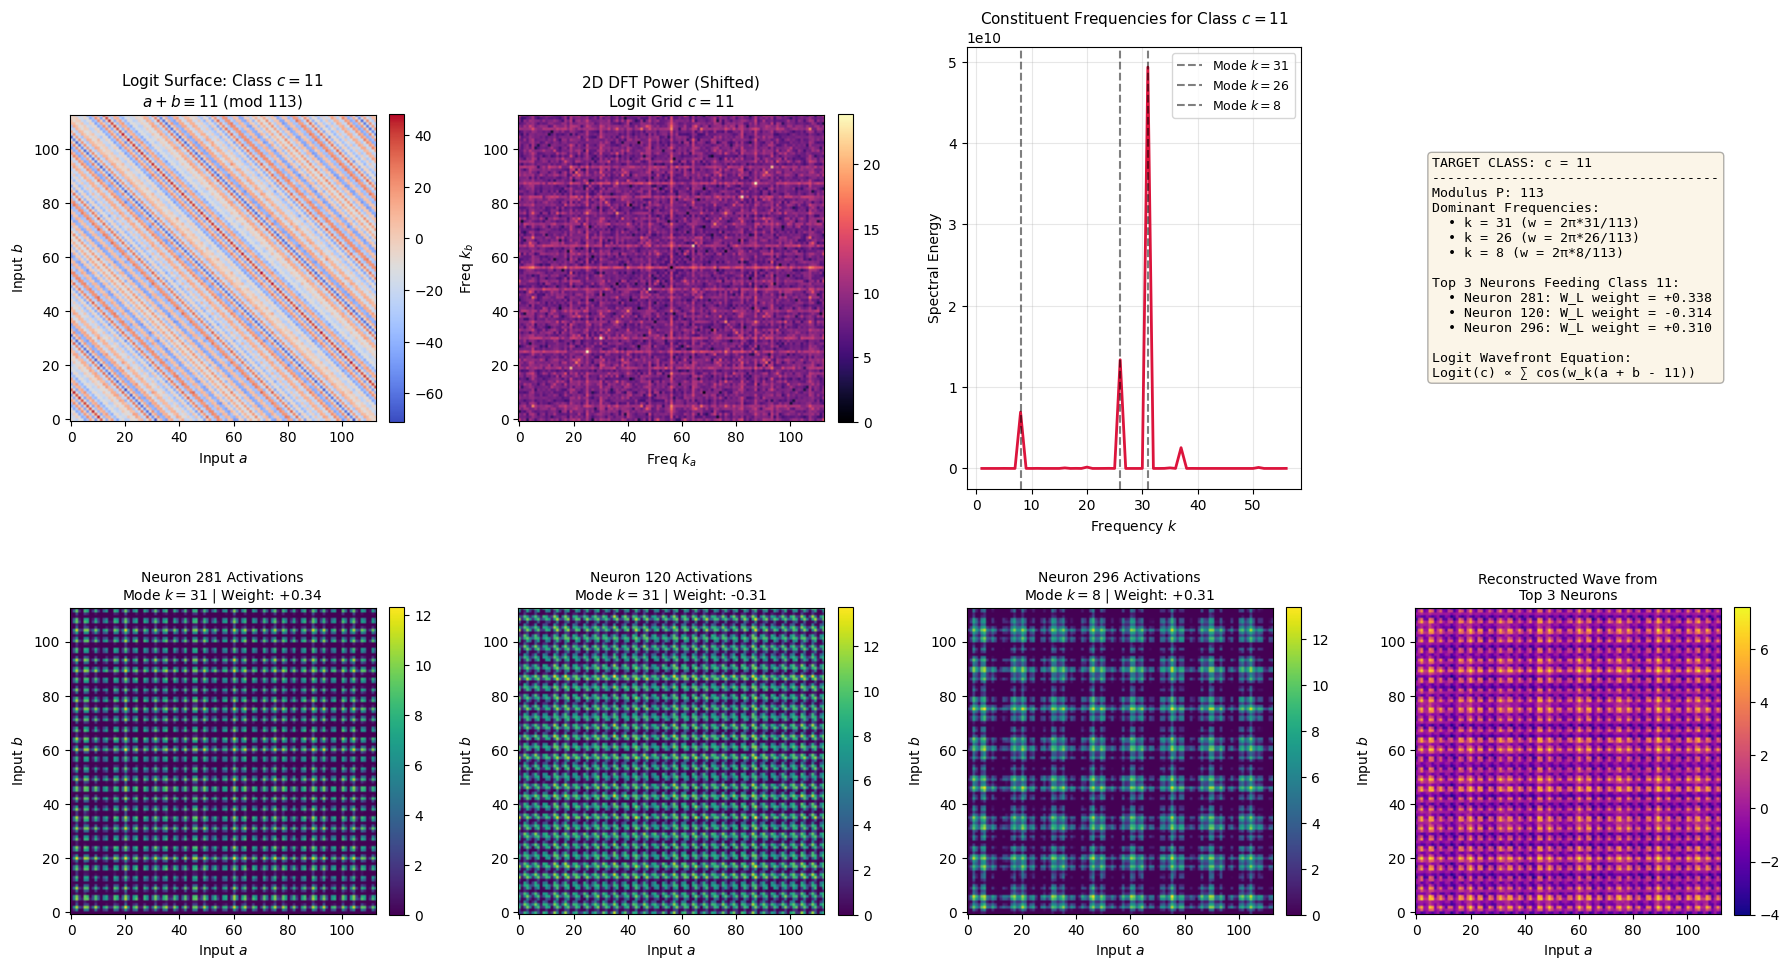

In [17]:
inspector = ModularArithmeticInspector(model, p=113)
inspector.inspect_class(target_c=11, top_neurons_k=3)

In [ ]:
# finding out whether the dominant frequency are even useful

def run_fourier_ablation_experiment(model, p=113, key_freqs=[8, 26, 31]):
    device = next(model.parameters()).device
    model.eval()

    # 1. Generate the complete grid of all p x p inputs and true targets
    grid_a, grid_b = torch.meshgrid(torch.arange(p), torch.arange(p), indexing='ij')
    all_a = grid_a.flatten().to(device)
    all_b = grid_b.flatten().to(device)
    all_eq = torch.full_like(all_a, p).to(device)
    full_inputs = torch.stack([all_a, all_b, all_eq], dim=1)
    full_targets = ((all_a + all_b) % p).to(device)

    # 2. Get unablated baseline logits
    with torch.no_grad():
        all_logits = model(full_inputs)  # (p*p, p)
        grid_logits = all_logits.view(p, p, p)

    criterion = nn.CrossEntropyLoss()
    base_loss = criterion(all_logits, full_targets).item()
    base_acc = (all_logits.argmax(-1) == full_targets).float().mean().item() * 100

    # 3. 2D FFT over input dimensions (a, b)
    fft_logits = torch.fft.fftn(grid_logits, dim=(0, 1))

    half_p = (p - 1) // 2
    ablation_losses = []
    ablation_accs = []
    all_freqs = list(range(1, half_p + 1))

    # Helper to create masks for a set of frequencies
    def make_mask(frequencies):
        mask = torch.zeros((p, p, 1), dtype=torch.bool, device=device)
        mask[0, 0, 0] = True  # Preserve DC constant offset
        for k in frequencies:
            mask[k, k, :] = True
            mask[p - k, p - k, :] = True
            mask[k, p - k, :] = True
            mask[p - k, k, :] = True
        return mask

    # --- Ablate each frequency individually ---
    for k in all_freqs:
        # Zero out only frequency k
        mask_k = make_mask([k])
        fft_ablated = fft_logits * (~mask_k)
        logits_ablated = torch.fft.ifftn(fft_ablated, dim=(0, 1)).real.view(p * p, p)

        loss_k = criterion(logits_ablated, full_targets).item()
        acc_k = (logits_ablated.argmax(-1) == full_targets).float().mean().item() * 100
        ablation_losses.append(loss_k)
        ablation_accs.append(acc_k)

    # --- Ablate ALL non-key frequencies (Restricted model) ---
    mask_key_only = make_mask(key_freqs)
    fft_restricted = fft_logits * mask_key_only
    logits_restricted = torch.fft.ifftn(fft_restricted, dim=(0, 1)).real.view(p * p, p)
    restr_loss = criterion(logits_restricted, full_targets).item()
    restr_acc = (logits_restricted.argmax(-1) == full_targets).float().mean().item() * 100

    # --- Ablate ALL key frequencies (Excluded model) ---
    fft_excluded = fft_logits * (~mask_key_only)
    logits_excluded = torch.fft.ifftn(fft_excluded, dim=(0, 1)).real.view(p * p, p)
    excl_loss = criterion(logits_excluded, full_targets).item()
    excl_acc = (logits_excluded.argmax(-1) == full_targets).float().mean().item() * 100

    # --- Visualization ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

    bar_colors = ['crimson' if k in key_freqs else 'steelblue' for k in all_freqs]

    # Plot 1: Loss upon ablating individual frequency k
    ax1.bar(all_freqs, ablation_losses, color=bar_colors, width=0.8)
    ax1.axhline(base_loss, color='black', linestyle='--', label=f'Baseline Loss ({base_loss:.2e})')
    ax1.set_yscale('log')
    ax1.set_title('Test Loss After Ablating Single Frequency $k$', fontsize=12)
    ax1.set_xlabel('Ablated Frequency $k$')
    ax1.set_ylabel('Cross-Entropy Loss (Log Scale)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Plot 2: Collective Ablation Comparison (Restricted vs Excluded)
    labels = ['Baseline', 'Restricted\n(Keep ONLY Key Freqs)', 'Excluded\n(Remove ALL Key Freqs)']
    losses = [base_loss, restr_loss, excl_loss]
    accs = [base_acc, restr_acc, excl_acc]
    colors = ['gray', 'forestgreen', 'darkred']

    bars = ax2.bar(labels, losses, color=colors, width=0.55)
    ax2.set_yscale('log')
    ax2.set_title('Restricted vs. Excluded Key Frequencies Ablation', fontsize=12)
    ax2.set_ylabel('Cross-Entropy Loss (Log Scale)')
    ax2.grid(True, alpha=0.3)

    for bar, acc, l_val in zip(bars, accs, losses):
        y_pos = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., y_pos * 1.5,
                 f'Loss: {l_val:.2e}\nAcc: {acc:.1f}%',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.show()

    # Diagnostic Summary Table
    print(f"{'Condition':<35} | {'Loss':<12} | {'Accuracy':<10}")
    print("-" * 65)
    print(f"{'Full Baseline Model':<35} | {base_loss:<12.4e} | {base_acc:.2f}%")
    print(f"{'Restricted (Key Frequencies Only)':<35} | {restr_loss:<12.4e} | {restr_acc:.2f}%")
    print(f"{'Excluded (Key Frequencies Zeroed)':<35} | {excl_loss:<12.4e} | {excl_acc:.2f}%")
    for k in key_freqs:
        idx = k - 1
        print(f"{f'Ablating Single Mode k={k}':<35} | {ablation_losses[idx]:<12.4e} | {ablation_accs[idx]:.2f}%")


    # Test with the 3 key frequencies from your run
run_fourier_ablation_experiment(model, p=113, key_freqs=[8, 26, 31])

In [9]:
# weight decay = 1.5 , 35k training steps --> identified key freq k = {8 , 26 , 49}

class GrokkingTransformer(nn.Module):
    def __init__(self, p=113, d_model=128, n_heads=4, d_mlp=512):
        super().__init__()
        self.p = p
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.d_mlp = d_mlp

        self.W_E = nn.Embedding(p + 1, d_model)
        self.W_pos = nn.Parameter(torch.randn(3, d_model) * (1.0 / np.sqrt(d_model)))

        self.W_Q = nn.Parameter(torch.randn(n_heads, d_model, self.d_head) / np.sqrt(d_model))
        self.W_K = nn.Parameter(torch.randn(n_heads, d_model, self.d_head) / np.sqrt(d_model))
        self.W_V = nn.Parameter(torch.randn(n_heads, d_model, self.d_head) / np.sqrt(d_model))
        self.W_O = nn.Parameter(torch.randn(n_heads, self.d_head, d_model) / np.sqrt(d_model))

        self.W_in = nn.Linear(d_model, d_mlp, bias=True)
        self.W_out = nn.Linear(d_mlp, d_model, bias=False)
        self.W_U = nn.Linear(d_model, p, bias=False)
        self.relu = nn.ReLU()

    def forward(self, x):
        h = self.W_E(x) + self.W_pos.unsqueeze(0)

        # Multi-Head Attention
        q = torch.einsum('bsd,hde->hbs e', h, self.W_Q)
        k = torch.einsum('bsd,hde->hbs e', h, self.W_K)
        v = torch.einsum('bsd,hde->hbs e', h, self.W_V)

        attn_scores = torch.einsum('hbse,hboe->hbso', q, k) / np.sqrt(self.d_head)
        attn_probs = torch.softmax(attn_scores, dim=-1)
        attn_out = torch.einsum('hbso,hboe->hbs e', attn_probs, v)
        mha_out = torch.einsum('hbs e,hed->bsd', attn_out, self.W_O)

        h = h + mha_out

        # Output branch on '=' token
        h_eq = h[:, 2, :]
        mlp_act = self.relu(self.W_in(h_eq))
        mlp_out = self.W_out(mlp_act)
        h_eq = h_eq + mlp_out

        return self.W_U(h_eq)


def get_fourier_projection(W_E_weights, p, k):
    theta = 2 * np.pi * k * np.arange(p) / p
    b_cos = np.cos(theta) * np.sqrt(2.0 / p)
    b_sin = np.sin(theta) * np.sqrt(2.0 / p)

    v_cos = b_cos @ W_E_weights
    v_sin = b_sin @ W_E_weights

    # Internal direction unit vectors
    norm_cos = np.linalg.norm(v_cos) + 1e-9
    norm_sin = np.linalg.norm(v_sin) + 1e-9
    u_hat = v_cos / norm_cos
    v_hat = v_sin / norm_sin

    # 2D coordinates for all P tokens
    x_coords = W_E_weights @ u_hat
    y_coords = W_E_weights @ v_hat
    return x_coords, y_coords

def compute_frequency_powers(W_E_weights, p):
    half_p = (p - 1) // 2
    powers = []
    for k in range(1, half_p + 1):
        theta = 2 * np.pi * k * np.arange(p) / p
        b_cos = np.cos(theta) * np.sqrt(2.0 / p)
        b_sin = np.sin(theta) * np.sqrt(2.0 / p)

        v_cos = b_cos @ W_E_weights
        v_sin = b_sin @ W_E_weights
        power = np.sum(v_cos**2) + np.sum(v_sin**2)
        powers.append((k, power))
    return powers

def train_and_record(
    p=113,
    train_split=0.4,
    total_steps=35000,
    lr=1e-3,
    weight_decay=1.5,
    snapshot_interval=200
):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Training on device: {device}")

    # Build dataset
    grid_a, grid_b = torch.meshgrid(torch.arange(p), torch.arange(p), indexing='ij')
    all_a = grid_a.flatten()
    all_b = grid_b.flatten()
    all_eq = torch.full_like(all_a, p)

    all_x = torch.stack([all_a, all_b, all_eq], dim=1)
    all_y = (all_a + all_b) % p

    total_samples = p * p
    n_train = int(train_split * total_samples)

    torch.manual_seed(1337)
    indices = torch.randperm(total_samples)
    train_idx, test_idx = indices[:n_train], indices[n_train:]

    train_x, train_y = all_x[train_idx].to(device), all_y[train_idx].to(device)
    test_x, test_y = all_x[test_idx].to(device), all_y[test_idx].to(device)

    model = GrokkingTransformer(p=p, d_model=128, n_heads=4, d_mlp=512).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay, betas=(0.9, 0.98))
    criterion = nn.CrossEntropyLoss()

    history = {
        'steps': [],
        'train_acc': [],
        'test_acc': [],
        'train_loss': [],
        'test_loss': [],
        'w_e_snapshots': []
    }

    print("Beginning training run...")
    for step in range(1, total_steps + 1):
        model.train()
        optimizer.zero_grad()
        logits = model(train_x)
        loss = criterion(logits, train_y)
        loss.backward()
        optimizer.step()

        if step % snapshot_interval == 0 or step == 1:
            model.eval()
            with torch.no_grad():
                train_acc = (logits.argmax(-1) == train_y).float().mean().item() * 100.0
                test_logits = model(test_x)
                test_loss = criterion(test_logits, test_y).item()
                test_acc = (test_logits.argmax(-1) == test_y).float().mean().item() * 100.0

                w_e = model.W_E.weight[:p].detach().cpu().numpy()

                history['steps'].append(step)
                history['train_acc'].append(train_acc)
                history['test_acc'].append(test_acc)
                history['train_loss'].append(loss.item())
                history['test_loss'].append(test_loss)
                history['w_e_snapshots'].append(w_e)

            if step % (snapshot_interval * 5) == 0:
                print(f"Step {step:5d} | Train Acc: {train_acc:6.2f}% | Test Acc: {test_acc:6.2f}% | Train Loss: {loss.item():.2e} | Test Loss: {test_loss:.2e}")

    return history, p


def generate_cleanup_gif(history, p=113, output_path="grokking_phases_cleanup.gif"):
    # Detect true dominant modes from final snapshot
    final_w_e = history['w_e_snapshots'][-1]
    powers = compute_frequency_powers(final_w_e, p)
    sorted_powers = sorted(powers, key=lambda x: x[1], reverse=True)

    key_freqs = [k for k, pwr in sorted_powers[:3]]
    non_key_freq = sorted_powers[-1][0]  # The weakest mode

    print(f"\nDiscovered Dominant Key Modes: {key_freqs}")
    print(f"Discovered Non-Key (Noise) Mode: k={non_key_freq}")

    snapshots = history['w_e_snapshots']
    steps = history['steps']
    train_accs = history['train_acc']
    test_accs = history['test_acc']

    fig, axes = plt.subplots(1, 4, figsize=(19, 5), dpi=100)
    plt.subplots_adjust(bottom=0.22, top=0.80, wspace=0.3)

    cmap = plt.cm.hsv
    colors = cmap(np.linspace(0, 1, p))

    def update(idx):
        for ax in axes:
            ax.clear()

        step = steps[idx]
        tr_acc = train_accs[idx]
        te_acc = test_accs[idx]
        w_e = snapshots[idx]

        # Phase labels
        if tr_acc < 99.0:
            phase_name = "Phase 1: Memorization (Fitting Training Data)"
            bar_color = "darkorange"
        elif tr_acc >= 99.0 and te_acc < 70.0:
            phase_name = "Phase 2: Representation Cleanup (Weight Decay Decays Noise Subspace)"
            bar_color = "crimson"
        else:
            phase_name = "Phase 3: Generalization (Fourier Rings Locked In)"
            bar_color = "forestgreen"

        fig.suptitle(
            f"Step: {step:05d}  |  Train Acc: {tr_acc:.1f}%  |  Test Acc: {te_acc:.1f}%\n{phase_name}",
            fontsize=14, fontweight='bold', color=bar_color
        )

        all_plot_freqs = key_freqs + [non_key_freq]
        titles = [
            f"Key Mode k = {key_freqs[0]}",
            f"Key Mode k = {key_freqs[1]}",
            f"Key Mode k = {key_freqs[2]}",
            f"Non-Key Mode k = {non_key_freq} (Noise)"
        ]

        for i, (k_val, title) in enumerate(zip(all_plot_freqs, titles)):
            ax = axes[i]
            x_coords, y_coords = get_fourier_projection(w_e, p, k_val)

            # Gray trace lines connecting 0 -> 1 -> 2 ...
            ax.plot(x_coords, y_coords, color='gray', alpha=0.35, linewidth=0.9, zorder=1)

            # Colored token scatter points
            ax.scatter(x_coords, y_coords, c=colors, s=35, edgecolors='black', linewidth=0.5, zorder=2)

            ax.axhline(0, color='gray', linestyle='--', linewidth=0.6, alpha=0.5)
            ax.axvline(0, color='gray', linestyle='--', linewidth=0.6, alpha=0.5)
            ax.set_xlim(-1.1, 1.1)
            ax.set_ylim(-1.1, 1.1)
            ax.set_aspect('equal')
            ax.grid(True, alpha=0.2)
            ax.set_title(title, fontsize=12, fontweight='bold', color='navy' if i < 3 else 'darkred')
            ax.set_xlabel(r"Projection on $\cos(\omega_k x)$", fontsize=9)
            ax.set_ylabel(r"Projection on $\sin(\omega_k x)$", fontsize=9)

    print("Rendering GIF animation...")
    ani = animation.FuncAnimation(fig, update, frames=len(snapshots), interval=80, repeat=True)
    ani.save(output_path, writer='pillow', fps=12)
    plt.close()
    print(f"Animation saved to: {output_path}")



history, p = train_and_record(
    p=113,
    train_split=0.4,
    total_steps=35000,
    lr=1e-3,
    weight_decay=1.5,
    snapshot_interval=200
)
generate_cleanup_gif(history, p=p, output_path="grokking_phases_cleanup.gif")

Training on device: cuda
Beginning training run...
Step  1000 | Train Acc: 100.00% | Test Acc:  39.44% | Train Loss: 1.10e-03 | Test Loss: 1.11e+01
Step  2000 | Train Acc: 100.00% | Test Acc:  39.62% | Train Loss: 1.37e-03 | Test Loss: 9.61e+00
Step  3000 | Train Acc: 100.00% | Test Acc:  39.89% | Train Loss: 6.57e-07 | Test Loss: 1.30e+01
Step  4000 | Train Acc: 100.00% | Test Acc:  47.21% | Train Loss: 5.03e-07 | Test Loss: 5.73e+00
Step  5000 | Train Acc: 100.00% | Test Acc: 100.00% | Train Loss: 2.41e-07 | Test Loss: 4.91e-05
Step  6000 | Train Acc: 100.00% | Test Acc: 100.00% | Train Loss: 5.47e-04 | Test Loss: 1.39e-03
Step  7000 | Train Acc: 100.00% | Test Acc: 100.00% | Train Loss: 2.05e-06 | Test Loss: 3.49e-05
Step  8000 | Train Acc: 100.00% | Test Acc: 100.00% | Train Loss: 3.41e-04 | Test Loss: 1.07e-03
Step  9000 | Train Acc: 100.00% | Test Acc: 100.00% | Train Loss: 4.50e-07 | Test Loss: 5.08e-05
Step 10000 | Train Acc: 100.00% | Test Acc: 100.00% | Train Loss: 4.05e-05 |